# DataPact - A6 Part 1: Hugging Face model lab (light models)

**INFO 490 MG, Team 15. Part 1 (Route A, prompt engineering): Hriday Agarwal.**

> **Why a "light" version?** The first notebook (`ai_prototype_full_range.ipynb`) went up to 8B-parameter
> models, and the free Colab session kept crashing while loading them (it runs out of its ~12 GB
> of system RAM). This version keeps the same task, test inputs, prompts and scoring, but every
> model is **under 2B parameters** (at most ~3.7 GB in 16-bit), so nothing needs 4-bit tricks.
> It also saves results after every model, so if Colab does disconnect, *Run all* again skips
> the models that already finished.

DataPact checks recurring data files against a versioned *data contract*. When a check fails,
someone has to decide whether the **data is wrong** or the **contract is out of date**. This
notebook tests whether a small local language model can help with that decision.

**The task given to every model.** One failed validation rule goes in (dataset, column, rule,
rows failed, sample values). The model must reply with only this JSON:

```json
{"explanation": "<one plain-English sentence>",
 "likely_cause": "DATA_ISSUE" | "CONTRACT_UPDATED",
 "suggested_action": "<one short sentence>"}
```

JSON matters because the Django view that uses the model has to parse the answer with code.

**What the notebook does**

1. Installs libraries (top cell).
2. Lists 15 openly downloadable light models in 5 size categories.
3. **Matrix test:** all 15 models on the same 8 fixed inputs, with the same zero-shot prompt.
4. **Route A:** the 3 best models re-tested with zero-, one-, few- and many-shot prompts.
5. **Evaluation:** structure, accuracy, speed and memory, plus a combined score.

**How to run it:** in Google Colab choose *Runtime > Change runtime type > T4 GPU*, then
*Runtime > Run all*. A full run takes roughly 20-30 minutes.
Setting `SMOKE_TEST = True` below runs a 2-model, 2-input version in a couple of minutes
(this is how the notebook was checked on a laptop before the Colab run).

## 1. Install libraries

* `transformers`: Hugging Face's library that downloads a model by name and runs it.
* `accelerate`: places the model on the GPU.

PyTorch (`torch`) is already installed on Colab. No `bitsandbytes` here: every model is small
enough to load at normal 16-bit precision.

In [1]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
packages = ["transformers==5.20.1", "accelerate==1.15.0", "pandas", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: True


## 2. Settings and the 15 models

Models were found through the Hugging Face Open LLM Leaderboard and model hub. Every one is
**not gated** (no login or licence approval needed), is an **instruct/chat** version (trained to
follow instructions, not just continue text), and loads with plain `transformers`. They come
from 9 different model families, so the comparison is not just one company's models at
different sizes.

Parameter counts are the real totals from each model's `safetensors` metadata, so a name can
mislead: "Falcon3-1B" is really 1.67B. All 15 models are light, so the categories split the
0.1B - 2B range, three models each:

| Category | Parameters | Memory in 16-bit |
|---|---|---|
| Ultra-light | 0.1B - 0.4B | under 1 GB |
| Light | 0.4B - 0.6B | about 1 GB |
| Small | 1.0B - 1.5B | 2 - 3 GB |
| Medium | 1.5B - 1.7B | about 3.3 GB |
| Large | 1.7B - 2.0B | about 3.6 GB |

"Large" here means the largest *of these light models*, not a 7B+ model.

In [2]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"  # set True for a quick check

MODELS = [
    # (category, Hugging Face id, parameters in billions)
    ("Ultra-light", "HuggingFaceTB/SmolLM2-135M-Instruct", 0.13),
    ("Ultra-light", "HuggingFaceTB/SmolLM-360M-Instruct", 0.36),
    ("Ultra-light", "HuggingFaceTB/SmolLM2-360M-Instruct", 0.36),
    ("Light", "Qwen/Qwen2-0.5B-Instruct", 0.49),
    ("Light", "Qwen/Qwen2.5-0.5B-Instruct", 0.49),
    ("Light", "h2oai/h2o-danube3-500m-chat", 0.51),
    ("Small", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", 1.10),
    ("Small", "ibm-granite/granite-3.1-1b-a400m-instruct", 1.33),
    ("Small", "allenai/OLMo-2-0425-1B-Instruct", 1.48),
    ("Medium", "Qwen/Qwen2.5-1.5B-Instruct", 1.54),
    ("Medium", "stabilityai/stablelm-2-zephyr-1_6b", 1.64),
    ("Medium", "tiiuae/Falcon3-1B-Instruct", 1.67),
    ("Large", "HuggingFaceTB/SmolLM2-1.7B-Instruct", 1.71),
    ("Large", "h2oai/h2o-danube2-1.8b-chat", 1.83),
    ("Large", "Qwen/Qwen1.5-1.8B-Chat", 1.84),
]
CATEGORY_ORDER = ["Ultra-light", "Light", "Small", "Medium", "Large"]
TOP_N_FOR_ROUTE_A = 3
MAX_NEW_TOKENS = 160

if SMOKE_TEST:
    MODELS = [m for m in MODELS if m[1] in (
        "HuggingFaceTB/SmolLM2-135M-Instruct", "Qwen/Qwen2.5-0.5B-Instruct")]
    TOP_N_FOR_ROUTE_A = 1

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Device:", DEVICE, "| smoke test:", SMOKE_TEST, "| models to test:", len(MODELS))
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda | smoke test: False | models to test: 15
GPU: Tesla T4


## 3. Downloading the model weights

The weights are the learned numbers inside each model, stored in `.safetensors` files.
`snapshot_download` saves them to the Hugging Face cache (outside the repository, so they can
never be committed).

Each model is downloaded right before its test. To keep disk use low, any model whose files
are **over 1 GB is deleted right after its test**; the small ones are kept. If a deleted model
makes the top 3, the Route A section downloads it again. A download that stalls (no data for
60 seconds) is retried up to 3 times, picking up where it stopped. The speed numbers only time the
model's answer, never the download, so none of this affects the comparison.

In [3]:
import shutil
import time

# Give up on a connection that sends nothing for 60 s (must be set before the import below).
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
from huggingface_hub import scan_cache_dir, snapshot_download

WEIGHT_FILES = ["*.json", "*.safetensors", "*.model", "*.txt", "*.py", "*.tiktoken"]
DELETE_ABOVE_GB = 1.0  # models bigger than this are deleted after their test


def free_gb():
    return shutil.disk_usage("/").free / 1e9


def size_on_disk_gb(model_id):
    for repo in scan_cache_dir().repos:
        if repo.repo_id == model_id:
            return repo.size_on_disk / 1e9
    return 0.0


def download(model_id, attempts=3):
    for attempt in range(1, attempts + 1):
        try:
            return snapshot_download(model_id, allow_patterns=WEIGHT_FILES)
        except Exception as error:  # a dropped connection resumes where it stopped
            print(f"   download attempt {attempt} failed: {type(error).__name__}")
            if attempt == attempts:
                raise
            time.sleep(10)


def tidy_up(model_id):
    size = size_on_disk_gb(model_id)
    if size > DELETE_ABOVE_GB:
        delete_from_cache(model_id)
        print(f"   deleted its {size:.1f} GB of files")


def delete_from_cache(model_id):
    for repo in scan_cache_dir().repos:
        if repo.repo_id == model_id:
            hashes = [rev.commit_hash for rev in repo.revisions]
            scan_cache_dir().delete_revisions(*hashes).execute()


print(f"Free disk: {free_gb():.1f} GB (models over {DELETE_ABOVE_GB:.0f} GB are deleted after testing)")

Free disk: 75.3 GB (models over 1 GB are deleted after testing)


## 4. The fixed inputs

**Test set:** 8 failed checks written in DataPact's own vocabulary, each with the right answer.
Four are bad data (impossible values, a placeholder like `-9999`, malformed IDs, duplicates) and
four are legitimate new values the contract does not know yet (a new enrolment status, a new
library branch, a new benefit code, a new winter term).

The 4/4 split is deliberate: a model that always answers `DATA_ISSUE` scores 50%, so accuracy
above 50% means the model is reading the evidence, not guessing.

**Example pool:** 12 more labelled cases, used only as worked examples in the Route A prompts.
None of them appears in the test set, so a model cannot score by copying an answer it was shown.

In [4]:
TEST_CASES = [
    dict(id="T1", dataset="Monthly Enrollment Export", column="credit_hours",
         rule='RANGE {"min": 0, "max": 24}', failed="47 of 4,812 rows",
         samples="[31, 99, -2]", label="DATA_ISSUE"),
    dict(id="T2", dataset="Monthly Enrollment Export", column="status",
         rule='ALLOWED_VALUES ["ENROLLED", "DROPPED", "WITHDRAWN"]', failed="4 of 4,812 rows",
         samples='["AUDIT", "AUDIT", "AUDIT", "AUDIT"]', label="CONTRACT_UPDATED"),
    dict(id="T3", dataset="Monthly Enrollment Export", column="student_id",
         rule='REGEX "^[0-9]{8}$"', failed="12 of 4,812 rows",
         samples='["1234567", "12345678A", "ABC00012"]', label="DATA_ISSUE"),
    dict(id="T4", dataset="Sensor Readings - Lab 3", column="temperature_c",
         rule='RANGE {"min": -10, "max": 50}', failed="6 of 8,640 rows",
         samples="[-9999, -9999, -9999]", label="DATA_ISSUE"),
    dict(id="T5", dataset="Library Circulation Log", column="branch",
         rule='ALLOWED_VALUES ["MAIN", "GRAINGER", "UNDERGRAD"]', failed="310 of 9,800 rows",
         samples='["FUNK_ACES", "FUNK_ACES", "FUNK_ACES"]', label="CONTRACT_UPDATED"),
    dict(id="T6", dataset="Payroll Deductions Export", column="deduction_code",
         rule='ALLOWED_VALUES ["FED", "STATE", "MEDICARE", "SOCSEC"]', failed="512 of 3,402 rows",
         samples='["HSA", "HSA", "HSA"]', label="CONTRACT_UPDATED"),
    dict(id="T7", dataset="Course Catalog Snapshot", column="term_code",
         rule='ALLOWED_VALUES ["FA", "SP", "SU"]', failed="85 of 2,100 rows",
         samples='["WI", "WI", "WI"]', label="CONTRACT_UPDATED"),
    dict(id="T8", dataset="Facilities Work Orders", column="order_id",
         rule="UNIQUE", failed="14 of 2,210 rows",
         samples='["WO-10233", "WO-10233", "WO-10871", "WO-10871"]', label="DATA_ISSUE"),
]

EXAMPLE_POOL = [
    (dict(dataset="Weekly Sales Extract", column="quantity", rule='RANGE {"min": 1, "max": 1000}',
          failed="9 of 13,120 rows", samples="[0, -3, 0]"),
     dict(explanation="Some sales rows have a quantity of zero or below, which cannot happen for a real sale.",
          likely_cause="DATA_ISSUE", suggested_action="Ask the sales team to correct the quantities in those rows.")),
    (dict(dataset="Monthly Enrollment Export", column="college", rule='ALLOWED_VALUES ["LAS", "ENG", "BUS", "ACES"]',
          failed="220 of 4,812 rows", samples='["CDS", "CDS", "CDS"]'),
     dict(explanation="Many students are listed under CDS, which looks like a newly created college rather than a typo.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm CDS is a real college and add it to the allowed values.")),
    (dict(dataset="Sensor Readings - Lab 3", column="humidity_pct", rule='TYPE_MATCH {"type": "number"}',
          failed="4 of 8,640 rows", samples='["N/A", "err", "N/A"]'),
     dict(explanation="A few humidity readings are text error markers instead of numbers.",
          likely_cause="DATA_ISSUE", suggested_action="Check the sensor logger and re-export the affected readings.")),
    (dict(dataset="Facilities Work Orders", column="priority", rule='ALLOWED_VALUES ["LOW", "MEDIUM", "HIGH"]',
          failed="140 of 2,210 rows", samples='["URGENT", "URGENT", "URGENT"]'),
     dict(explanation="Work orders now use an URGENT priority that the contract does not list yet.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm URGENT is an official priority and add it to the contract.")),
    (dict(dataset="Library Circulation Log", column="checkout_date", rule="NOT_NULL",
          failed="2 of 9,800 rows", samples="[null, null]"),
     dict(explanation="Two checkouts are missing their date, which every checkout must have.",
          likely_cause="DATA_ISSUE", suggested_action="Find the missing dates in the circulation system and fix the export.")),
    (dict(dataset="Course Catalog Snapshot", column="credit_hours", rule='RANGE {"min": 1, "max": 5}',
          failed="18 of 2,100 rows", samples="[6, 6, 6]"),
     dict(explanation="Several courses are worth 6 credits, consistent with a newly approved capstone format.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm the 6-credit courses and raise the maximum to 6.")),
    (dict(dataset="Payroll Deductions Export", column="employee_id", rule="UNIQUE",
          failed="5 of 3,402 rows", samples='["E1001", "E1001", "E2044"]'),
     dict(explanation="Some employee IDs appear more than once, so the same people were exported twice.",
          likely_cause="DATA_ISSUE", suggested_action="Remove the duplicate rows and check why the export repeated them.")),
    (dict(dataset="Weekly Sales Extract", column="region", rule='ALLOWED_VALUES ["NORTH", "SOUTH", "EAST", "WEST"]',
          failed="1,500 of 13,120 rows", samples='["ONLINE", "ONLINE", "ONLINE"]'),
     dict(explanation="A large, consistent block of sales is tagged ONLINE, which looks like a new sales channel.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm ONLINE is a real region and add it to the contract.")),
    (dict(dataset="Monthly Enrollment Export", column="email", rule='REGEX "^[^@]+@illinois\\.edu$"',
          failed="7 of 4,812 rows", samples='["jdoe@illinois", "@illinois.edu"]'),
     dict(explanation="A few email addresses are incomplete and would not work.",
          likely_cause="DATA_ISSUE", suggested_action="Correct the malformed addresses at the source.")),
    (dict(dataset="Sensor Readings - Lab 3", column="sensor_id", rule='ALLOWED_VALUES ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8"]',
          failed="720 of 8,640 rows", samples='["S9", "S9", "S9"]'),
     dict(explanation="Readings arrive steadily from a sensor S9, which suggests a new sensor was installed.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm sensor S9 exists and add it to the allowed list.")),
    (dict(dataset="Facilities Work Orders", column="cost_usd", rule='TYPE_MATCH {"type": "number"}',
          failed="3 of 2,210 rows", samples='["$1,200", "TBD"]'),
     dict(explanation="A few costs were typed as text with symbols or placeholders instead of numbers.",
          likely_cause="DATA_ISSUE", suggested_action="Re-enter those costs as plain numbers.")),
    (dict(dataset="Library Circulation Log", column="item_type", rule='ALLOWED_VALUES ["BOOK", "DVD", "JOURNAL"]',
          failed="410 of 9,800 rows", samples='["LAPTOP", "LAPTOP", "LAPTOP"]'),
     dict(explanation="Many loans are for laptops, which matches a new lending service the contract predates.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm laptop lending and add LAPTOP to the allowed values.")),
]

SHOT_COUNTS = {"zero-shot": 0, "one-shot": 1, "few-shot": 3, "many-shot": 12}

if SMOKE_TEST:
    TEST_CASES = [TEST_CASES[0], TEST_CASES[1]]

print(len(TEST_CASES), "test cases,", len(EXAMPLE_POOL), "pool examples")

8 test cases, 12 pool examples


## 5. Building the prompt

Chat models expect a list of messages (`user`, `assistant`) that each model's **chat template**
turns into its own special format. The examples for one/few/many-shot are added as earlier
user-assistant turns, so the model sees "question, ideal answer" pairs before the real question.

The instructions go in the user message, not a system message, because not every model's
template supports a system role.

In [5]:
import json

INSTRUCTIONS = (
    "You review failed data-quality checks for DataPact. A failure means either the incoming "
    "data is wrong (DATA_ISSUE) or the data is legitimate and the rule is out of date "
    "(CONTRACT_UPDATED).\n"
    "Reply with ONLY a JSON object, no other text, with exactly these keys:\n"
    '  "explanation": one plain-English sentence,\n'
    '  "likely_cause": "DATA_ISSUE" or "CONTRACT_UPDATED",\n'
    '  "suggested_action": one short sentence.'
)


def describe(case):
    return (
        f"Dataset: {case['dataset']}\nColumn: {case['column']}\nRule: {case['rule']}\n"
        f"Rows failed: {case['failed']}\nSample values: {case['samples']}"
    )


def build_messages(case, n_shots):
    messages = []
    for i, (example, answer) in enumerate(EXAMPLE_POOL[:n_shots]):
        text = describe(example)
        if i == 0:
            text = INSTRUCTIONS + "\n\n" + text
        messages.append({"role": "user", "content": text})
        messages.append({"role": "assistant", "content": json.dumps(answer)})
    question = describe(case)
    if n_shots == 0:
        question = INSTRUCTIONS + "\n\n" + question
    messages.append({"role": "user", "content": question})
    return messages


print("Zero-shot prompt for T1:\n")
print(build_messages(TEST_CASES[0], 0)[-1]["content"])

Zero-shot prompt for T1:

You review failed data-quality checks for DataPact. A failure means either the incoming data is wrong (DATA_ISSUE) or the data is legitimate and the rule is out of date (CONTRACT_UPDATED).
Reply with ONLY a JSON object, no other text, with exactly these keys:
  "explanation": one plain-English sentence,
  "likely_cause": "DATA_ISSUE" or "CONTRACT_UPDATED",
  "suggested_action": one short sentence.

Dataset: Monthly Enrollment Export
Column: credit_hours
Rule: RANGE {"min": 0, "max": 24}
Rows failed: 47 of 4,812 rows
Sample values: [31, 99, -2]


## 6. Loading, running and scoring a model

* **Loading.** Every model loads in 16-bit floats (2 bytes per parameter), so the largest one
  needs about 3.7 GB of the T4's 15 GB. On the GPU, `device_map` streams the weights straight
  into GPU memory instead of first copying them into Colab's smaller system RAM.
* **Generating.** Greedy decoding (`do_sample=False`): the model always picks its single most
  likely next token, so a rerun gives the same answer. That makes the comparison repeatable.
* **Scoring.** The first `{...}` in the reply is parsed as JSON, then checked for the three keys
  and an allowed `likely_cause`, then compared with the correct answer.
* **Memory** is the peak GPU memory used while the model answered (CUDA only).

In [6]:
import gc
import re
import time

from transformers import AutoModelForCausalLM, AutoTokenizer

REQUIRED_KEYS = {"explanation", "likely_cause", "suggested_action"}
CAUSES = {"DATA_ISSUE", "CONTRACT_UPDATED"}


def load(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    kwargs = {"dtype": torch.float16 if DEVICE != "cpu" else torch.float32}
    if DEVICE == "cuda":
        kwargs["device_map"] = "cuda"
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if DEVICE != "cuda":
        model.to(DEVICE)
    model.eval()
    return tokenizer, model


def unload(model):
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def generate(tokenizer, model, messages):
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(
            **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
            pad_token_id=tokenizer.pad_token_id)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return text, seconds, len(new_tokens), inputs["input_ids"].shape[1]


def score(text, label):
    result = {"valid_json": False, "schema_ok": False, "correct": False, "predicted": None}
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        return result
    try:
        data = json.loads(match.group(0))
    except json.JSONDecodeError:
        return result
    if not isinstance(data, dict):
        return result
    result["valid_json"] = True
    cause = str(data.get("likely_cause", "")).strip().upper()
    result["predicted"] = cause or None
    result["schema_ok"] = REQUIRED_KEYS.issubset(data) and cause in CAUSES
    result["correct"] = cause == label
    return result


def run(model_id, category, n_shots, method):
    tokenizer, model = load(model_id)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    rows = []
    for case in TEST_CASES:
        text, seconds, n_new, n_prompt = generate(tokenizer, model, build_messages(case, n_shots))
        rows.append({
            "model": model_id.split("/")[-1], "model_id": model_id, "category": category,
            "method": method, "case": case["id"], "label": case["label"],
            "prompt_tokens": n_prompt, "new_tokens": n_new, "seconds": round(seconds, 2),
            "tokens_per_s": round(n_new / seconds, 1) if seconds else None,
            "output": text, **score(text, case["label"]),
        })
    peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else None
    for row in rows:
        row["peak_mem_gb"] = round(peak_gb, 2) if peak_gb else None
    unload(model)
    return rows

## 7. Matrix test: 15 models x 8 inputs, zero-shot

Every model gets exactly the same zero-shot prompt, so differences come from the model alone.
Each model is downloaded, loaded, run on all 8 inputs and unloaded before the next one, so only
one model is in memory at a time (and models over 1 GB are deleted from disk straight after).

**Crash-safe:** the CSV is rewritten after every model. If the session crashes or you restart
it, *Run all* again picks up where it stopped (finished models are skipped). If Colab fully
disconnects and gives you a new machine, the files are gone and it starts from the beginning.

In [7]:
import pandas as pd

os.makedirs("results", exist_ok=True)
SIZE = {model_id: params for _, model_id, params in MODELS}
MATRIX_CSV = "results/matrix_results.csv"


def load_saved(path):
    if os.path.exists(path):
        return pd.read_csv(path).to_dict("records")
    return []


matrix_rows = load_saved(MATRIX_CSV)
done = {row["model_id"] for row in matrix_rows}
if done:
    print("Resuming: already finished", len(done), "models")

for category, model_id, params in MODELS:
    if model_id in done:
        continue
    print(f"[{category}] {model_id} ...", flush=True)
    try:
        download(model_id)
        matrix_rows += run(model_id, category, 0, "zero-shot")
    except Exception as error:  # one broken model should not stop the other 14
        print("   failed:", type(error).__name__, error)
    tidy_up(model_id)
    pd.DataFrame(matrix_rows).to_csv(MATRIX_CSV, index=False)

matrix = pd.DataFrame(matrix_rows)
matrix = matrix[matrix["model_id"].isin(SIZE)]
matrix["params_b"] = matrix["model_id"].map(SIZE)
matrix.to_csv(MATRIX_CSV, index=False)
print("Saved", MATRIX_CSV, "with", len(matrix), "rows from", matrix["model_id"].nunique(), "models")

[Ultra-light] HuggingFaceTB/SmolLM2-135M-Instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[Ultra-light] HuggingFaceTB/SmolLM-360M-Instruct ...


...

   deleted its 3.7 GB of files
[Large] Qwen/Qwen1.5-1.8B-Chat ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

   deleted its 3.7 GB of files
Saved results/matrix_results.csv with 120 rows from 15 models


### Matrix results by model

* `json_%`: replies a program could parse. `schema_%`: right keys and an allowed cause.
* `accuracy_%`: `likely_cause` matched the right answer (50% = guessing).
* `score`: combined ranking used to pick the Route A models -
  **40% schema + 40% accuracy + 20% speed**, speed relative to the fastest model.
  Structure counts as much as accuracy because the app cannot use an answer it cannot parse.

In [8]:
def summarise(frame, by):
    summary = frame.groupby(by, sort=False).agg(
        json_pct=("valid_json", "mean"), schema_pct=("schema_ok", "mean"),
        accuracy_pct=("correct", "mean"), sec_per_answer=("seconds", "mean"),
        tokens_per_s=("tokens_per_s", "mean"), peak_mem_gb=("peak_mem_gb", "max"),
    )
    for col in ("json_pct", "schema_pct", "accuracy_pct"):
        summary[col] = (summary[col] * 100).round(0)
    summary["sec_per_answer"] = summary["sec_per_answer"].round(2)
    summary["tokens_per_s"] = summary["tokens_per_s"].round(1)
    speed = summary["tokens_per_s"] / summary["tokens_per_s"].max()
    summary["score"] = (0.4 * summary["schema_pct"] + 0.4 * summary["accuracy_pct"]
                        + 20 * speed).round(1)
    return summary


by_model = summarise(matrix, ["category", "model", "model_id"]).reset_index()
by_model["params_b"] = by_model["model_id"].map(SIZE)
by_model.drop(columns="model_id").sort_values("score", ascending=False)

,category,model,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb,score,params_b
12,Large,SmolLM2-1.7B-Instruct,100.0,100.0,75.0,1.99,35.7,3.50,85.7,1.71
8,Small,OLMo-2-0425-1B-Instruct,100.0,100.0,50.0,1.90,41.5,3.03,78.2,1.48
14,Large,Qwen1.5-1.8B-Chat,100.0,100.0,50.0,3.48,35.0,3.76,75.4,1.84
6,Small,TinyLlama-1.1B-Chat-v1.0,100.0,100.0,50.0,4.61,33.7,2.24,74.8,1.10
10,Medium,stablelm-2-zephyr-1_6b,100.0,88.0,50.0,2.71,44.1,3.38,74.6,1.64
4,Light,Qwen2.5-0.5B-Instruct,100.0,100.0,50.0,2.21,29.5,1.02,73.0,0.49
9,Medium,Qwen2.5-1.5B-Instruct,100.0,100.0,50.0,3.24,25.0,3.12,71.0,1.54
13,Large,h2o-danube2-1.8b-chat,62.0,62.0,25.0,3.08,29.6,3.72,47.8,1.83
3,Light,Qwen2-0.5B-Instruct,100.0,38.0,12.0,2.67,29.5,1.01,33.0,0.49
5,Light,h2o-danube3-500m-chat,0.0,0.0,0.0,3.52,45.5,1.06,20.0,0.51


In [9]:
by_category = summarise(matrix, ["category"]).reindex(
    [c for c in CATEGORY_ORDER if c in set(matrix["category"])])
by_category

,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb,score
category,,,,,,,
Ultra-light,4.0,4.0,4.0,5.16,21.9,0.76,15.8
Light,67.0,46.0,21.0,2.80,34.8,1.06,46.7
Small,92.0,71.0,33.0,3.46,32.9,3.03,60.5
Medium,67.0,62.0,33.0,2.67,34.9,3.38,58.0
Large,88.0,88.0,50.0,2.85,33.5,3.76,74.4


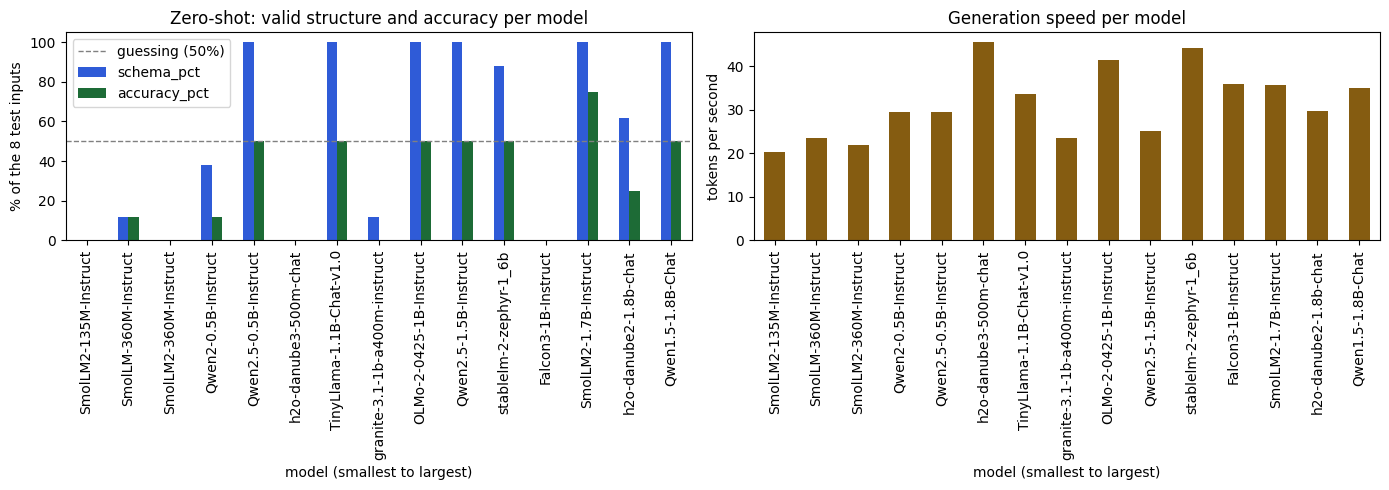

In [10]:
import matplotlib.pyplot as plt

plot = by_model.set_index("model").reindex(
    by_model.sort_values("params_b")["model"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot[["schema_pct", "accuracy_pct"]].plot.bar(ax=axes[0], color=["#2f5bd7", "#1d6b36"])
axes[0].set_title("Zero-shot: valid structure and accuracy per model")
axes[0].set_ylabel("% of the 8 test inputs")
axes[0].axhline(50, color="grey", linestyle="--", linewidth=1, label="guessing (50%)")
axes[0].legend()
axes[0].set_xlabel("model (smallest to largest)")
plot["tokens_per_s"].plot.bar(ax=axes[1], color="#855c11")
axes[1].set_title("Generation speed per model")
axes[1].set_ylabel("tokens per second")
axes[1].set_xlabel("model (smallest to largest)")
plt.tight_layout()
plt.savefig("results/matrix_chart.png", dpi=120)
plt.show()

## 8. Route A: zero-, one-, few- and many-shot prompting

The top models from the matrix test are re-run with 0, 1, 3 and 12 worked examples in front of
the real question. Same 8 test inputs, same scoring. The question: **which prompting method
gives the most reliable structure (and correct answers) for DataPact?**

More examples usually teach the format better but make the prompt longer, which costs time on
every request. `prompt_tokens` shows how much longer.

In [11]:
top_models = (by_model.sort_values("score", ascending=False)
              .head(TOP_N_FOR_ROUTE_A)[["category", "model_id"]].values.tolist())
print("Route A models:", [m for _, m in top_models])

ROUTE_CSV = "results/prompting_results.csv"
route_rows = load_saved(ROUTE_CSV)
done = {(row["model_id"], row["method"]) for row in route_rows}

for category, model_id in top_models:
    todo = [(m, n) for m, n in SHOT_COUNTS.items() if (model_id, m) not in done]
    if not todo:
        continue
    download(model_id)
    for method, n_shots in todo:
        print(f"{model_id} - {method}", flush=True)
        try:
            route_rows += run(model_id, category, n_shots, method)
        except Exception as error:
            print("   failed:", type(error).__name__, error)
        pd.DataFrame(route_rows).to_csv(ROUTE_CSV, index=False)
    tidy_up(model_id)

route = pd.DataFrame(route_rows)
route.to_csv(ROUTE_CSV, index=False)
print("Saved", ROUTE_CSV, "with", len(route), "rows")

Route A models: ['HuggingFaceTB/SmolLM2-1.7B-Instruct', 'allenai/OLMo-2-0425-1B-Instruct', 'Qwen/Qwen1.5-1.8B-Chat']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

HuggingFaceTB/SmolLM2-1.7B-Instruct - zero-shot


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

...

Qwen/Qwen1.5-1.8B-Chat - few-shot


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Qwen/Qwen1.5-1.8B-Chat - many-shot


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

   deleted its 3.7 GB of files
Saved results/prompting_results.csv with 96 rows


In [12]:
by_method = summarise(route, ["model", "method"]).drop(columns="score")
by_method["prompt_tokens"] = route.groupby(["model", "method"], sort=False)["prompt_tokens"].mean().round(0)
by_method

json_pct  schema_pct  accuracy_pct  \
model                   method                                          
SmolLM2-1.7B-Instruct   zero-shot     100.0       100.0          75.0   
                        one-shot      100.0       100.0          50.0   
                        few-shot      100.0       100.0         100.0   
                        many-shot     100.0       100.0          62.0   
OLMo-2-0425-1B-Instruct zero-shot     100.0       100.0          50.0   
                        one-shot      100.0       100.0          62.0   
                        few-shot      100.0       100.0          50.0   
                        many-shot     100.0       100.0          50.0   
Qwen1.5-1.8B-Chat       zero-shot     100.0       100.0          50.0   
                        one-shot      100.0        75.0          50.0   
                        few-shot      100.0        88.0          75.0   
                        many-shot     100.0       100.0          75.0   

                                   sec_per_answer  tokens_per_s  peak_mem_gb  \
model                   method                                                 
SmolLM2-1.7B-Instruct   zero-shot            1.91          37.1         3.52   
                        one-shot             1.73          36.8         3.54   
                        few-shot             1.53          35.4         3.59   
                        many-shot            1.94          27.5         3.90   
OLMo-2-0425-1B-Instruct zero-shot            1.90          41.5         3.05   
                        one-shot             1.56          41.1         3.06   
                        few-shot             1.36          40.2         3.08   
                        many-shot            1.54          34.0         3.28   
Qwen1.5-1.8B-Chat       zero-shot            3.48          35.0         3.76   
                        one-shot             1.98          34.9         3.78   
                        few-shot             1.59          33.7         3.83   
                        many-shot            1.76          28.7         4.08   

                                   prompt_tokens  
model                   method                    
SmolLM2-1.7B-Instruct   zero-shot          214.0  
                        one-shot           339.0  
                        few-shot           602.0  
                        many-shot         1769.0  
OLMo-2-0425-1B-Instruct zero-shot          163.0  
                        one-shot           278.0  
                        few-shot           509.0  
                        many-shot         1553.0  
Qwen1.5-1.8B-Chat       zero-shot          178.0  
                        one-shot           296.0  
                        few-shot           530.0  
                        many-shot         1592.0

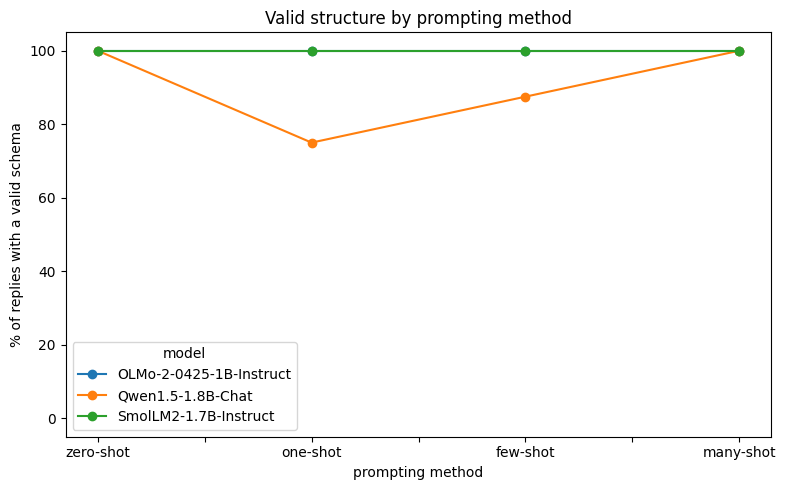

In [13]:
methods = list(SHOT_COUNTS)
pivot = (route.groupby(["method", "model"])["schema_ok"].mean().unstack() * 100).reindex(methods)
ax = pivot.plot(marker="o", figsize=(8, 5))
ax.set_title("Valid structure by prompting method")
ax.set_ylabel("% of replies with a valid schema")
ax.set_xlabel("prompting method")
ax.set_ylim(-5, 105)
plt.tight_layout()
plt.savefig("results/prompting_chart.png", dpi=120)
plt.show()

## 9. Evaluation

Criteria the team uses to compare models, in order of importance for DataPact:

1. **Instruction adherence (structure).** Does the reply parse as JSON with the right keys? The
   Django view cannot use anything else.
2. **Reasoning (accuracy).** Does it tell bad data from an outdated contract? 50% is guessing.
3. **Speed.** Seconds per answer and tokens per second, since a user waits for it.
4. **Footprint.** Parameters and peak memory, which decide what server it needs.

The cell below states the results from the numbers above, so the summary always matches the run.

In [14]:
best_overall = by_model.sort_values("score", ascending=False).iloc[0]
best_per_category = (by_model.sort_values("score", ascending=False)
                     .groupby("category").head(1).set_index("category")
                     .reindex([c for c in CATEGORY_ORDER if c in set(by_model["category"])]))
method_rank = summarise(route, ["method"]).sort_values(
    ["schema_pct", "accuracy_pct"], ascending=False)

print(f"Best model overall: {best_overall['model']} ({best_overall['params_b']}B, "
      f"{best_overall['category']}) - schema {best_overall['schema_pct']:.0f}%, "
      f"accuracy {best_overall['accuracy_pct']:.0f}%, {best_overall['sec_per_answer']}s per answer")
print("\nBest model in each category:")
for category, row in best_per_category.iterrows():
    print(f"  {category:12} {row['model']:34} schema {row['schema_pct']:>3.0f}%  "
          f"accuracy {row['accuracy_pct']:>3.0f}%  {row['sec_per_answer']}s")
print("\nPrompting methods (averaged over the Route A models), best first:")
for method, row in method_rank.iterrows():
    print(f"  {method:10} schema {row['schema_pct']:>3.0f}%  accuracy {row['accuracy_pct']:>3.0f}%  "
          f"{row['sec_per_answer']}s per answer")

Best model overall: SmolLM2-1.7B-Instruct (1.71B, Large) - schema 100%, accuracy 75%, 1.99s per answer

Best model in each category:
  Ultra-light  SmolLM-360M-Instruct               schema  12%  accuracy  12%  6.51s
  Light        Qwen2.5-0.5B-Instruct              schema 100%  accuracy  50%  2.21s
  Small        OLMo-2-0425-1B-Instruct            schema 100%  accuracy  50%  1.9s
  Medium       stablelm-2-zephyr-1_6b             schema  88%  accuracy  50%  2.71s
  Large        SmolLM2-1.7B-Instruct              schema 100%  accuracy  75%  1.99s

Prompting methods (averaged over the Route A models), best first:
  many-shot  schema 100%  accuracy  62%  1.75s per answer
  zero-shot  schema 100%  accuracy  58%  2.43s per answer
  few-shot   schema  96%  accuracy  75%  1.49s per answer
  one-shot   schema  92%  accuracy  54%  1.75s per answer


In [15]:
# A few raw replies, to show what "valid" and "invalid" look like in practice.
sample = matrix.sort_values(["schema_ok", "params_b"]).groupby("schema_ok").head(3)
for _, row in sample.iterrows():
    print(f"--- {row['model']} on {row['case']} (schema ok: {row['schema_ok']}) ---")
    print(row["output"][:400], "\n")

--- SmolLM2-135M-Instruct on T1 (schema ok: False) ---
{"explanation": "The data is invalid due to a data entry error. The rule is out of date. The data is invalid due to a data entry error. The data is invalid due to a data entry error. The data is invalid due to a data entry error. The data is invalid due to a data entry error. The data is invalid due to a data entry error. The data is invalid due to a data entry error. The data is invalid due to a  

--- SmolLM2-135M-Instruct on T2 (schema ok: False) ---
{"explanation": "The data is invalid due to a data inconsistency. The rule is out of date. The data is not eligible for enrollment. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is invalid. The data is inva 

--- SmolLM2-135M-Instruct on T3 (schema ok: False) ---
{"explanation": "The data is 

## 10. Findings

*Written after the full Colab run (T4 GPU, 19 Oct 2026), from the tables above. With only 8
test inputs, each input is worth 12.5 points, so 75% vs 100% is a difference of two answers.*

**1. Below 0.5B the models cannot do the task.** The Ultra-light category produced valid
structure on 4% of inputs. SmolLM2-135M repeats one sentence until it is cut off, SmolLM2-360M
leaves out the `{ }` entirely, and SmolLM-360M answered only 1 of 8.

**2. A 50% score usually means the model is not reasoning.** The balanced 4/4 test set exposes
this. Qwen2.5-0.5B, Qwen2.5-1.5B, TinyLlama-1.1B and Qwen1.5-1.8B answered `DATA_ISSUE` for
all 8 inputs, StableLM-2-1.6B for 7 of 8, and OLMo-2-1B answered `CONTRACT_UPDATED` for all 8.
All of them land on 50% by repeating one label. **Only SmolLM2-1.7B actually told the two causes
apart** in the zero-shot test (75% correct, split 4/4 between the labels).

**3. Size sweet spot: about 1.5B - 1.8B, but size alone is not enough.** The Large category
(1.7B - 1.8B) had the best average (88% valid structure, 50% accuracy) against 46% / 21% for
Light. But two models near the top size failed on formatting habits rather than reasoning:
Falcon3-1B (1.67B) wrote correct-looking JSON without the commas between keys (0% valid), and
H2O-Danube2-1.8B escaped underscores the way Markdown does (`credit\_hours`), which breaks
JSON (62% valid). Granite-3.1-1B wrote sentences where the label should be. The model family's
training matters as much as the parameter count.

**4. Most reliable prompting method: few-shot (3 examples).** Averaged over the 3 Route A
models:

| Method | Valid structure | Accuracy | Prompt tokens | Seconds per answer |
|---|---|---|---|---|
| zero-shot | 100% | 58% | ~185 | 2.43 |
| one-shot | 92% | 54% | ~305 | 1.75 |
| few-shot | 96% | **75%** | ~547 | **1.49** |
| many-shot | 100% | 62% | ~1,638 | 1.75 |

Few-shot gave the best accuracy and the fastest answers, because the examples teach the model
to answer briefly (54 new tokens on average against 91 for zero-shot). One example can backfire:
with one-shot, SmolLM2-1.7B answered `DATA_ISSUE` for all 8 inputs, the same label as its single
example. Many-shot made the prompt about 9x longer than zero-shot without beating few-shot.

The ranking printed in section 9 lists many-shot first because it sorts by valid structure
before accuracy. Many-shot leads there by a single reply (24 of 24 valid against 23 of 24),
while few-shot got 3 more causes right (18 of 24 against 15 of 24) and answered faster, so
few-shot is the better choice overall.

**5. Recommended for the Django integration: `HuggingFaceTB/SmolLM2-1.7B-Instruct` with the
few-shot prompt.** It was the only combination with 100% valid structure *and* 100% correct
causes (8 of 8), at 1.5 s per answer and about 3.6 GB of GPU memory in 16-bit. That is the
practical cost to plan for: on a CPU-only server it needs roughly 7 GB of RAM at 32-bit, more
than a free hosting tier provides. Second choice: Qwen1.5-1.8B-Chat with few-shot or many-shot
(75% correct).

## 11. Download the results (Colab only)

Zips the `results/` folder (two CSVs and two charts) and downloads it, so the files can be
added to `llm-test/results_light/` in the repository. Then save this notebook with
*File > Download > Download .ipynb* so its outputs are kept.

In [16]:
if IN_COLAB:
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")
else:
    print("Not in Colab - results are already in ./results")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>